In [1]:
%load_ext autoreload
%autoreload 2
import numpy as np
import matplotlib.pyplot as plt
from coffea import util
from coffea.processor import accumulate
import os
import re
import pandas as pd
import hist
import matplotlib as mpl
import mplhep
import sys
import hist
import hist.intervals


sys.path.append("/uscms/home/reshmar/nobackup/IDMe_Run3_Collab/CMSSW_13_0_13/src/iDMe/python_analysis/analysisTools")
import plotTools as ptools
import utils

In [2]:

f_sig = "/uscms/home/reshmar/nobackup/IDMe_Run3_Collab/CMSSW_13_0_13/src/iDMe/python_analysis/coffea/VertexRes2026/VtxResdRcut1.coffea"


# The file is reloaded in the next cell on every run.

In [3]:
# Edit the sample configuration here, then rerun this cell and the cells below.
# This cell rebuilds BOTH numerator and denominator together.
samples = {
    10: 
    {
        
        0.2: [100],
    },
    # 20: 
    # {
        
    #     0.2: [100],
        
    # },
    # 30: 
    # {
       
    #     0.2: [100]
    # },
    # 40: 
    # {
    #     0.2: [100],
    # },
    50:
    {
        
        0.2: [100],
    },
    # 60:
    # {
        
    #      0.1: [100],
    #      0.2: [100]
    
    # },
    # 70:
    # {    0.1: [100],
    #      0.2: [100],
    # },
    # 80:
    # {    0.1: [100],
    #      0.2: [100],
    # },
    # 90:
    # {    0.1: [100],
    #      0.2: [100],
    # },
    100:
    {    
         0.2: [100],
    }
}

cut = 'cut1'
year = 2022

# Clear previous counts before loading; a failed run must not leave old counts.
sum_counts = sum_counts_den = None
sum_edges_pt = sum_edges_vxy = None
sum_edges_pt_den = sum_edges_vxy_den = None
sig_histo = None
sig_histo = util.load(f_sig)[0]


def fresh_counts(variable):
    # These variables are local and start empty on every call.
    counts_by_sample = []
    pt_edges = vxy_edges = None
    for m1, deltas in samples.items():
        for delta, ctaus in deltas.items():
            for ctau in ctaus:
                fig, ax = plt.subplots(figsize=(7, 7))
                plot_dict = {'variable': variable, 'cut': cut, 'year': year}
                style_2d_dict = {
                    'fig': fig, 'ax': ax, 'xrebin': None, 'yrebin': None,
                    'xlim': None, 'ylim': None, 'doLogy': False,
                    'doLogx': False, 'doLogz': True,
                    'xlabel': 'gen vtx pT (in GeV)',
                    'ylabel': 'gen vtx vxy (in cm)', 'zlabel': 'Counts',
                    'flow': None, 'doSave': False,
                    'outDir': './plots/signal_2018', 'outName': 'ptvslxy.png'
                }
                try:
                    result = ptools.plot_signal_2D(
                        sig_histo, m1, delta, ctau, plot_dict, style_2d_dict)
                    counts = np.asarray(result[0], dtype=float)
                    xedges = np.asarray(result[1], dtype=float)
                    yedges = np.asarray(result[2], dtype=float)
                    if pt_edges is None:
                        pt_edges, vxy_edges = xedges, yedges
                    elif not (np.array_equal(pt_edges, xedges)
                              and np.array_equal(vxy_edges, yedges)):
                        raise ValueError('Selected samples have different bin edges.')
                    counts_by_sample.append(counts)
                    print(f'{variable}: m1={m1}, delta={delta}, ctau={ctau}, sum={counts.sum():g}')
                finally:
                    plt.close(fig)
    if not counts_by_sample:
        raise ValueError('Choose at least one sample.')
    return np.sum(np.stack(counts_by_sample), axis=0), pt_edges, vxy_edges


# Assign globals only after BOTH extractions succeed.
def rebuild_counts():
    numerator = fresh_counts('genvtx_pt_vxy')
    denominator = fresh_counts('genvtx_pt_vxy_den')
    if not (np.array_equal(numerator[1], denominator[1])
            and np.array_equal(numerator[2], denominator[2])):
        raise ValueError('Numerator and denominator bin edges differ.')
    return (*numerator, *denominator)

print('Reloaded file:', f_sig)
print('Selected samples:', samples)
(sum_counts, sum_edges_pt, sum_edges_vxy,
 sum_counts_den, sum_edges_pt_den, sum_edges_vxy_den) = rebuild_counts()

print('sum_counts=', sum_counts)
print('sum_edges_pt=', sum_edges_pt)
print('sum_edges_vxy=', sum_edges_vxy)


Reloaded file: /uscms/home/reshmar/nobackup/IDMe_Run3_Collab/CMSSW_13_0_13/src/iDMe/python_analysis/coffea/VertexRes2026/VertexEffRRcut2.coffea
Selected samples: {10: {0.2: [100]}, 50: {0.2: [100]}, 100: {0.2: [100]}}
genvtx_pt_vxy: m1=10, delta=0.2, ctau=100, sum=1452
genvtx_pt_vxy: m1=50, delta=0.2, ctau=100, sum=16654
genvtx_pt_vxy: m1=100, delta=0.2, ctau=100, sum=27510
genvtx_pt_vxy_den: m1=10, delta=0.2, ctau=100, sum=481388
genvtx_pt_vxy_den: m1=50, delta=0.2, ctau=100, sum=1.06346e+06
genvtx_pt_vxy_den: m1=100, delta=0.2, ctau=100, sum=979651
sum_counts= [[1.2750e+03 3.1200e+02 1.2000e+01 0.0000e+00 0.0000e+00]
 [4.6010e+03 1.1360e+03 4.1000e+01 0.0000e+00 1.0000e+00]
 [1.5058e+04 5.7620e+03 2.5200e+02 8.0000e+00 0.0000e+00]
 [1.0191e+04 6.6310e+03 3.2800e+02 8.0000e+00 0.0000e+00]]
sum_edges_pt= [ 0.  5. 10. 20. 30.]
sum_edges_vxy= [ 0.  1.  5. 10. 15. 20.]


In [4]:
# Denominator was rebuilt with the numerator in the previous cell.
# There is no second sample configuration or separate accumulation loop.
print("sum_counts_den=", sum_counts_den)
print("sum_edges_pt_den=", sum_edges_pt_den)
print("sum_edges_vxy_den=", sum_edges_vxy_den)


sum_counts_den= [[ 63591. 159979. 115880.  74516.  52953.]
 [114422. 253136. 160385.  96139.  65150.]
 [138094. 337918. 224841. 133710.  88785.]
 [ 52662. 154776. 117177.  72726.  47662.]]
sum_edges_pt_den= [ 0.  5. 10. 20. 30.]
sum_edges_vxy_den= [ 0.  1.  5. 10. 15. 20.]


In [5]:
def eff_determine_unc(n, d):
    eff = np.divide(n, d)
    unc = hist.intervals.ratio_uncertainty(n, d, 'efficiency')
    return eff, unc


efficiency_lpt, unc_lpt = eff_determine_unc(sum_counts, sum_counts_den)
print ("efficiency_lpt=", efficiency_lpt)
print ("unc_lpt=", unc_lpt)

efficiency_lpt= [[2.00500071e-02 1.95025597e-03 1.03555402e-04 0.00000000e+00
  0.00000000e+00]
 [4.02107986e-02 4.48770621e-03 2.55634879e-04 0.00000000e+00
  1.53491942e-05]
 [1.09041667e-01 1.70514740e-02 1.12079203e-03 5.98309775e-05
  0.00000000e+00]
 [1.93517147e-01 4.28425596e-02 2.79918414e-03 1.10001925e-04
  0.00000000e+00]]
unc_lpt= [[[5.56093033e-04 1.10256548e-04 2.94716649e-05 0.00000000e+00
   0.00000000e+00]
  [5.81098343e-04 1.32847032e-04 3.97563188e-05 0.00000000e+00
   1.26975664e-05]
  [8.39537188e-04 2.22754185e-04 7.05217045e-05 2.07041467e-05
   0.00000000e+00]
  [1.72513902e-03 5.14989991e-04 1.54287211e-04 3.80650998e-05
   0.00000000e+00]]

 [[5.71401464e-04 1.16659633e-04 3.93466797e-05 2.47060887e-05
   3.47664843e-05]
  [5.89195519e-04 1.36820266e-04 4.64760355e-05 1.91493985e-05
   3.52949859e-05]
  [8.45223816e-04 2.25631554e-04 7.50993736e-05 2.95038912e-05
   2.07355134e-05]
  [1.73684271e-03 5.20934397e-04 1.63008425e-04 5.42421902e-05
   3.86258673e-

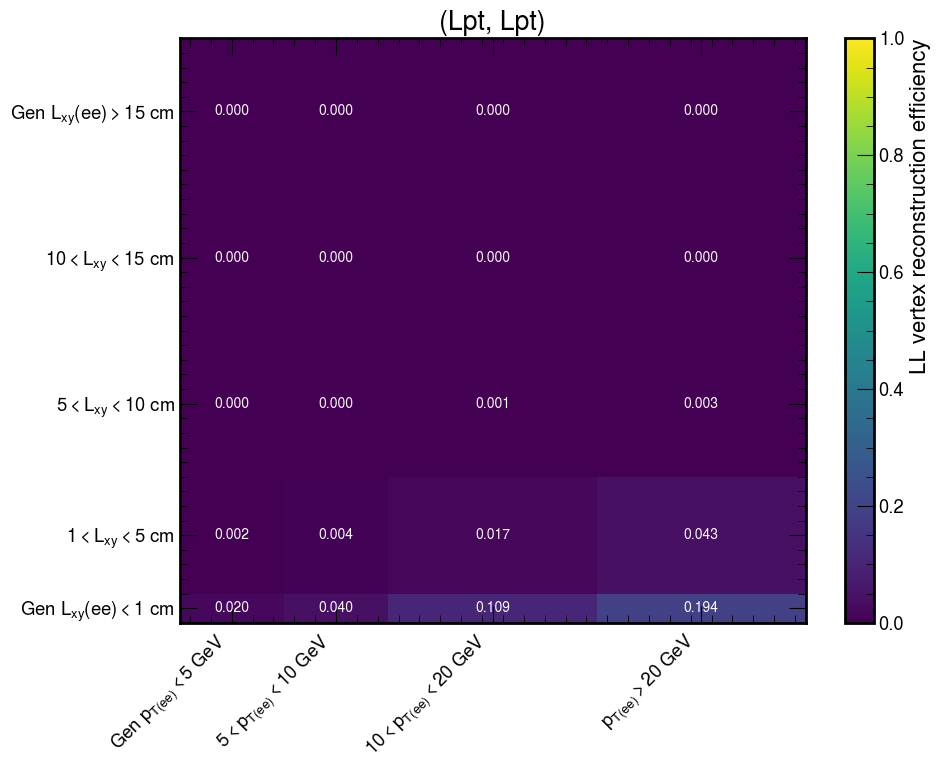

In [6]:
# Calculate the 2D efficiency safely
efficiency_lpt = np.divide(
    sum_counts,
    sum_counts_den,
    out=np.full_like(sum_counts, np.nan, dtype=float),
    where=(sum_counts_den > 0)
)

efficiency_to_plot = efficiency_lpt.T

fig, ax = plt.subplots(figsize=(10, 8))

mesh = ax.pcolormesh(
    sum_edges_pt,
    sum_edges_vxy,
    efficiency_to_plot,
    cmap="viridis",
    shading="auto",
    vmin=0,
    vmax=1
)

cbar = fig.colorbar(mesh, ax=ax)
cbar.set_label("LL vertex reconstruction efficiency")

# Calculate bin centers
pt_centers = 0.5 * (sum_edges_pt[:-1] + sum_edges_pt[1:])
vxy_centers = 0.5 * (sum_edges_vxy[:-1] + sum_edges_vxy[1:])

# Add efficiency values inside the boxes
for vxy_index, vxy_center in enumerate(vxy_centers):
    for pt_index, pt_center in enumerate(pt_centers):

        efficiency = efficiency_to_plot[vxy_index, pt_index]

        # Leave bins with no denominator events blank
        if np.isnan(efficiency):
            continue

        text_color = "white" if efficiency < 0.5 else "black"

        ax.text(
            pt_center,
            vxy_center,
            f"{efficiency:.3f}",
            # f"{100 * efficiency:.2f}%",
            ha="center",
            va="center",
            color=text_color,
            fontsize=10
        )

# Create x-axis labels automatically from the actual pT edges
x_labels = []

for index in range(len(pt_centers)):
    low_edge = sum_edges_pt[index]
    high_edge = sum_edges_pt[index + 1]

    if index == 0:
        label = rf"Gen $p_{{\mathrm{{T}}(ee)}} < {high_edge:g}$ GeV"
    elif index == len(pt_centers) - 1:
        label = rf"$p_{{\mathrm{{T}}(ee)}} > {low_edge:g}$ GeV"
    else:
        label = (
            rf"${low_edge:g} < p_{{\mathrm{{T}}(ee)}}"
            rf" < {high_edge:g}$ GeV"
        )

    x_labels.append(label)

# Create y-axis labels automatically from the actual vxy edges
y_labels = []

for index in range(len(vxy_centers)):
    low_edge = sum_edges_vxy[index]
    high_edge = sum_edges_vxy[index + 1]

    if index == 0:
        label = rf"Gen $L_{{xy}}(ee) < {high_edge:g}$ cm"
    elif index == len(vxy_centers) - 1:
        label = rf"Gen $L_{{xy}}(ee) > {low_edge:g}$ cm"
    else:
        label = rf"${low_edge:g} < L_{{xy}} < {high_edge:g}$ cm"

    y_labels.append(label)

# Set custom tick positions and labels
ax.set_xticks(pt_centers)
ax.set_xticklabels(
    x_labels,
    rotation=45,
    ha="right"
)

ax.set_yticks(vxy_centers)
ax.set_yticklabels(y_labels)

ax.set_xlabel("")
ax.set_ylabel("")
ax.set_title("(Lpt, Lpt)")

plt.tight_layout()
plt.show()

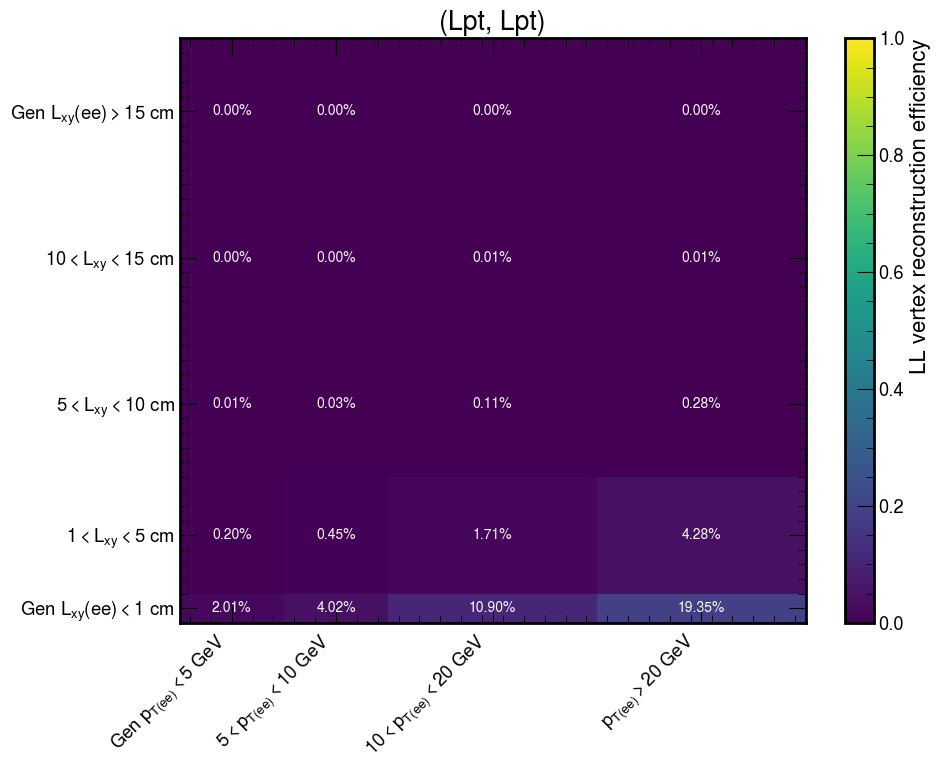

In [7]:
# Calculate the 2D efficiency safely
efficiency_lpt = np.divide(
    sum_counts,
    sum_counts_den,
    out=np.full_like(sum_counts, np.nan, dtype=float),
    where=(sum_counts_den > 0)
)

efficiency_to_plot = efficiency_lpt.T

fig, ax = plt.subplots(figsize=(10, 8))

mesh = ax.pcolormesh(
    sum_edges_pt,
    sum_edges_vxy,
    efficiency_to_plot,
    cmap="viridis",
    shading="auto",
    vmin=0,
    vmax=1
)

cbar = fig.colorbar(mesh, ax=ax)
cbar.set_label("LL vertex reconstruction efficiency")

# Calculate bin centers
pt_centers = 0.5 * (sum_edges_pt[:-1] + sum_edges_pt[1:])
vxy_centers = 0.5 * (sum_edges_vxy[:-1] + sum_edges_vxy[1:])

# Add efficiency values inside the boxes
for vxy_index, vxy_center in enumerate(vxy_centers):
    for pt_index, pt_center in enumerate(pt_centers):

        efficiency = efficiency_to_plot[vxy_index, pt_index]

        # Leave bins with no denominator events blank
        if np.isnan(efficiency):
            continue

        text_color = "white" if efficiency < 0.5 else "black"

        ax.text(
            pt_center,
            vxy_center,
            # f"{efficiency:.2f}",
            f"{100 * efficiency:.2f}%",
            ha="center",
            va="center",
            color=text_color,
            fontsize=10
        )

# Create x-axis labels automatically from the actual pT edges
x_labels = []

for index in range(len(pt_centers)):
    low_edge = sum_edges_pt[index]
    high_edge = sum_edges_pt[index + 1]

    if index == 0:
        label = rf"Gen $p_{{\mathrm{{T}}(ee)}} < {high_edge:g}$ GeV"
    elif index == len(pt_centers) - 1:
        label = rf"$p_{{\mathrm{{T}}(ee)}} > {low_edge:g}$ GeV"
    else:
        label = (
            rf"${low_edge:g} < p_{{\mathrm{{T}}(ee)}}"
            rf" < {high_edge:g}$ GeV"
        )

    x_labels.append(label)

# Create y-axis labels automatically from the actual vxy edges
y_labels = []

for index in range(len(vxy_centers)):
    low_edge = sum_edges_vxy[index]
    high_edge = sum_edges_vxy[index + 1]

    if index == 0:
        label = rf"Gen $L_{{xy}}(ee) < {high_edge:g}$ cm"
    elif index == len(vxy_centers) - 1:
        label = rf"Gen $L_{{xy}}(ee) > {low_edge:g}$ cm"
    else:
        label = rf"${low_edge:g} < L_{{xy}} < {high_edge:g}$ cm"

    y_labels.append(label)

# Set custom tick positions and labels
ax.set_xticks(pt_centers)
ax.set_xticklabels(
    x_labels,
    rotation=45,
    ha="right"
)

ax.set_yticks(vxy_centers)
ax.set_yticklabels(y_labels)

ax.set_xlabel("")
ax.set_ylabel("")
ax.set_title("(Lpt, Lpt)")

plt.tight_layout()
plt.show()

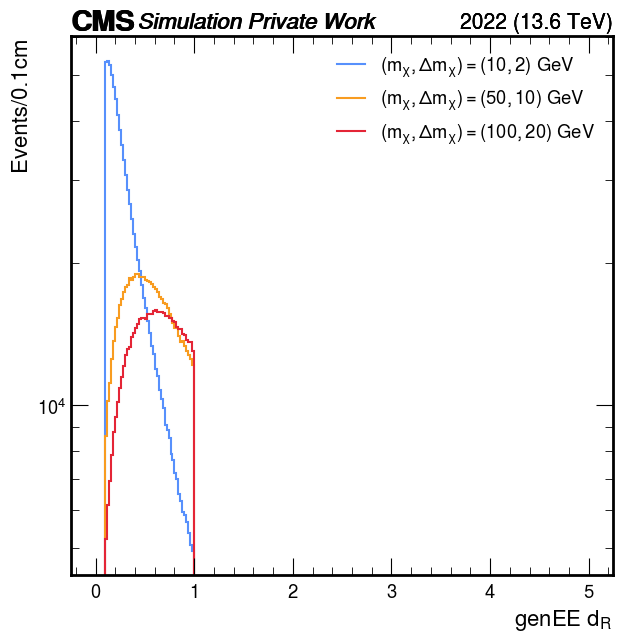

In [8]:
fig, ax = plt.subplots(figsize=(7,7))


# Plot settings
plot_dict = {
    'variable':'genEEdR',
    'cut': 'cut2',
    'year': 2022
}

style_dict = {
        'fig': fig,
        'ax': ax,
        'rebin': 1j,
        'xlim': [0,5],     # if None, the default will show up; otherwise give as a list, i.e. [0, 10]
        'doLogy': True, 
        'doLogx': False,
        'doDensity': False,
        'doYerr': False, 
        'xlabel': r"genEE $d_{R}$ ",   # if None, the default will show up; otherwise give as a string, i.e. 'Electron dxy'
        'ylabel': 'Events/0.1cm',   # if None, the default will show up; otherwise give as a string, i.e. 'Efficiency'
        'label': None,    # if None, the default will show up; otherwise give as a string, i.e. 'Highest ctau signal samples'
        'flow': None,     # overflow
        'doSave': False,
        'outDir': './plots/',
        'outName': f'background_cut7_Lxy_max10.png'
    }

#signal points
samples = {
    10: 
    {
        
        0.2: [100],
    },
    # 20: 
    # {
        
    #     0.2: [100],
        
    # },
    # 30: 
    # {
       
    #     0.2: [100]
    # },
    # 40: 
    # {
    #     0.2: [100],
    # },
    50:
    {
        
        0.2: [100],
    },
    # 60:
    # {
        
    #      0.1: [100],
    #      0.2: [100]
    
    # },
    # 70:
    # {    0.1: [100],
    #      0.2: [100],
    # },
    # 80:
    # {
    # # {    0.1: [100],
    #      0.2: [100],
    # },
    # 90:
    # {    0.1: [100],
    #      0.2: [100],
    # },
    100:
    {
    # {    0.1: [100],
         0.2: [100],
    }
}


h_list_lpt_den=[]
h_sum_lpt_den = None


for m1,deltas in samples.items():
    for delta, ctaus in deltas.items():
        for ctau in ctaus:
            h_lpt_den = ptools.plot_signal_1D(sig_histo, m1, delta, ctau, plot_dict, style_dict)
            